# Class 01 — Introduction to Machine Learning
### AI Engineer Full Roadmap
**Instructor:** Firoj Kawser Jubayer

---

We build **one** model, end to end, on a single dataset: predicting whether an SME
loan will default.

| Section | What we do |
|---|---|
| 1 | Load the data and look at it |
| 2 | Separate features (X) from the target (y) |
| 3 | Minimum cleaning so we can model today |
| 4 | Train / test split |
| 5 | Train the first model |
| 6 | `predict()` vs `predict_proba()` |
| 7 | Why accuracy lies |
| 8 | Confusion matrix, precision, recall |
| 9 | Moving the threshold |
| 10 | Overfitting, demonstrated live |

> **Dataset:** `loan_data.csv` — 10,038 SME loan applications with 16 columns.
> It is synthetic, but the flaws in it are the flaws you meet in real bank data.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

print("pandas", pd.__version__)
print("numpy ", np.__version__)

pandas 3.0.2
numpy  2.4.4


## 1. Load the data and look at it

Rule from the slides: **run these five before you form a single opinion.**

In [2]:
df = pd.read_csv("loan_data.csv")

df.shape          # (rows, columns) — how big is the problem?

(10038, 16)

In [3]:
df.head()         # what does one actual record look like?

,customer_id,age,monthly_income,employment_years,credit_score,num_dependents,existing_loans,loan_amount,loan_term_months,interest_rate,collateral_value,branch_code,district,product_type,defaulted,days_past_due_final
0,BA101507,36.0,50600.0,14.1,476.0,2,1,1356000.0,48,10.71,154000.0,138,Chattogram,Working Capital,0,0
1,BA108210,33.0,NaN,NaN,512.0,4,0,225000.0,24,11.49,304000.0,118,Chattogram,Working Capital,0,5
2,BA101455,35.0,51800.0,NaN,758.0,2,2,1147000.0,60,13.64,1971000.0,123,Dhaka,Working Capital,0,0
3,BA105323,51.0,119000.0,5.2,614.0,1,1,3510000.0,24,14.18,6509000.0,133,Dhaka,Working Capital,0,0
4,BA108724,40.0,44900.0,NaN,644.0,1,1,411000.0,24,13.42,510000.0,124,Chattogram,Working Capital,0,0


In [4]:
df.info()         # dtype and non-null count for every column

<class 'pandas.DataFrame'>
RangeIndex: 10038 entries, 0 to 10037
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   customer_id          10038 non-null  str    
 1   age                  9957 non-null   float64
 2   monthly_income       8215 non-null   float64
 3   employment_years     6891 non-null   float64
 4   credit_score         9064 non-null   float64
 5   num_dependents       10038 non-null  int64  
 6   existing_loans       10038 non-null  int64  
 7   loan_amount          10038 non-null  float64
 8   loan_term_months     10038 non-null  int64  
 9   interest_rate        10038 non-null  float64
 10  collateral_value     9427 non-null   float64
 11  branch_code          10038 non-null  int64  
 12  district             10038 non-null  str    
 13  product_type         10038 non-null  str    
 14  defaulted            10038 non-null  int64  
 15  days_past_due_final  10038 non-null  int64  
dt

In [5]:
df.describe().T   # min / max / mean / quartiles — look for impossible values

,count,mean,std,min,25%,50%,75%,max
age,9957.0,4.135724e+01,1.126268e+01,21.0,34.00,41.00,48.00,220.0
monthly_income,8215.0,6.240596e+04,3.808999e+04,0.0,36800.00,53600.00,77600.00,850800.0
employment_years,6891.0,6.193412e+00,3.825281e+00,0.1,3.40,5.40,8.20,38.9
credit_score,9064.0,6.596129e+02,8.384469e+01,370.0,604.00,659.00,718.00,850.0
num_dependents,10038.0,1.807133e+00,1.361251e+00,0.0,1.00,2.00,3.00,8.0
existing_loans,10038.0,8.974895e-01,9.370713e-01,0.0,0.00,1.00,1.00,6.0
loan_amount,10038.0,1.285845e+06,4.091150e+06,59000.0,599000.00,997000.00,1607000.00,400000000.0
loan_term_months,10038.0,3.646025e+01,1.827016e+01,12.0,24.00,36.00,48.00,84.0
interest_rate,10038.0,1.178123e+01,1.898970e+00,7.0,10.47,11.77,13.08,18.0
collateral_value,9427.0,1.195101e+06,1.231785e+06,0.0,362000.00,821000.00,1606000.00,13149000.0


In [6]:
df.isnull().sum().sort_values(ascending=False)   # exactly where the gaps are

employment_years       3147
monthly_income         1823
credit_score            974
collateral_value        611
age                      81
customer_id               0
existing_loans            0
num_dependents            0
loan_amount               0
loan_term_months          0
interest_rate             0
branch_code               0
district                  0
product_type              0
defaulted                 0
days_past_due_final       0
dtype: int64

### What we already learned in 30 seconds

- `employment_years` is missing for about **31%** of rows.
- `age` has a **maximum of 220** — nobody is 220 years old. That is a data entry error.
- `loan_amount` has a maximum of **400,000,000 BDT** (40 crore). That one is probably *real*.
- `branch_code` is stored as an integer, but branch 138 is not "bigger" than branch 137.

We will deal with all of this properly in **Class 02 (EDA)**. Today we do the minimum
required to get a model running.

## 2. Features and target

Every supervised problem reduces to the same two objects:

- **X** — the feature matrix, the inputs.
- **y** — the target vector, the single thing we are predicting.

In [7]:
df["defaulted"].value_counts()

defaulted
0    9198
1     840
Name: count, dtype: int64

In [8]:
df["defaulted"].value_counts(normalize=True).round(4) * 100
# ~8.4% of loans default. Remember this number — it comes back in section 7.

defaulted
0    91.63
1     8.37
Name: proportion, dtype: float64

### The leaky column

`days_past_due_final` is recorded **after** we already know whether the loan went bad.
A loan cannot be 176 days past due unless it has already defaulted.

If we leave it in, the model will score near-perfectly in the notebook and be **useless
in production**, because at the moment of a real credit decision that column does not exist yet.

This is called **data leakage** and it is the single most common way a promising model
dies after deployment.

In [9]:
# Proof: the leaky column almost perfectly separates the two classes
df.groupby("defaulted")["days_past_due_final"].describe()[["mean", "min", "max"]]

,mean,min,max
defaulted,,,
0,7.645684,0.0,30.0
1,248.554762,92.0,399.0


In [10]:
LEAKY   = ["days_past_due_final"]
ID_COLS = ["customer_id"]
TARGET  = "defaulted"

df = df.drop(columns=LEAKY + ID_COLS)
print("Columns remaining:", list(df.columns))

Columns remaining: ['age', 'monthly_income', 'employment_years', 'credit_score', 'num_dependents', 'existing_loans', 'loan_amount', 'loan_term_months', 'interest_rate', 'collateral_value', 'branch_code', 'district', 'product_type', 'defaulted']


## 3. Minimum cleaning

Not a full clean — just enough to train. Each decision below is a choice we
will revisit and justify properly in Class 02.

In [11]:
# 3a. Duplicated rows: the same customer counted twice biases the model toward them.
print("Duplicated rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after dropping duplicates:", df.shape)

Duplicated rows: 38
Shape after dropping duplicates: (10000, 14)


In [12]:
# 3b. Impossible values -> treat as missing, not as data.
df.loc[df["age"] > 100, "age"] = np.nan
df.loc[df["monthly_income"] == 0, "monthly_income"] = np.nan

# 3c. branch_code is a label, not a quantity. Store it as a string so nothing
#     downstream treats 138 > 137 as meaningful.
df["branch_code"] = df["branch_code"].astype("string")

df[["age", "monthly_income"]].describe().T

,count,mean,std,min,25%,50%,75%,max
age,9911.0,41.196650,9.902857,21.0,34.0,41.0,48.0,74.0
monthly_income,8176.0,62464.077789,38088.540981,6700.0,36900.0,53600.0,77600.0,850800.0


In [13]:
# 3d. Fill the gaps.
#     MEDIAN, not mean — income is heavily right-skewed and the mean is dragged
#     upward by a handful of very large values.
num_cols = df.select_dtypes(include="number").columns.drop(TARGET)

for col in num_cols:
    if df[col].isnull().any():
        median = df[col].median()
        df[col] = df[col].fillna(median)
        print(f"{col:<20} filled with median = {median:,.0f}")

print("\nRemaining nulls:", int(df.isnull().sum().sum()))

age                  filled with median = 41
monthly_income       filled with median = 53,600
employment_years     filled with median = 5
credit_score         filled with median = 659
collateral_value     filled with median = 821,000

Remaining nulls: 0


> **Note for later.** Filling 31% of a column with one number is a big assumption.
> In Class 02 we will look at whether the *absence itself* predicts default — often it does,
> and then an `is_missing` flag is better than any fill.

In [14]:
# 3e. Categorical columns -> one-hot encoding (models need numbers).
X = df.drop(columns=[TARGET])
y = df[TARGET]

X = pd.get_dummies(X, columns=["district", "product_type", "branch_code"],
                   drop_first=True)

print("X shape:", X.shape)
print("y shape:", y.shape)
X.head(3)

X shape: (10000, 79)
y shape: (10000,)


,age,monthly_income,employment_years,credit_score,num_dependents,existing_loans,loan_amount,loan_term_months,interest_rate,collateral_value,district_Chattogram,district_Dhaka,district_Khulna,district_Rajshahi,district_Rangpur,...,branch_code_146,branch_code_147,branch_code_148,branch_code_149,branch_code_150,branch_code_151,branch_code_152,branch_code_153,branch_code_154,branch_code_155,branch_code_156,branch_code_157,branch_code_158,branch_code_159,branch_code_160
0,36.0,50600.0,14.1,476.0,2,1,1356000.0,48,10.71,154000.0,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,33.0,53600.0,5.4,512.0,4,0,225000.0,24,11.49,304000.0,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,35.0,51800.0,5.4,758.0,2,2,1147000.0,60,13.64,1971000.0,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


## 4. Train / test split

The most important two lines in the whole notebook.

- `test_size=0.2` → 80% to learn from, 20% locked away.
- `stratify=y` → keeps the 8.4% default rate identical in both halves. Without this,
  a random split can leave the test set with a noticeably different class balance.
- `random_state=42` → fixes the shuffle so your numbers match your classmate's.

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42,
)

print(f"Training rows: {len(X_train):,}   default rate: {y_train.mean():.2%}")
print(f"Test rows:     {len(X_test):,}   default rate: {y_test.mean():.2%}")

Training rows: 8,000   default rate: 8.34%
Test rows:     2,000   default rate: 8.35%


> From this line until section 9, **we do not touch `X_test` or `y_test`.**
> Looking at the test set to make a decision is the same as giving students the exam paper early.

## 5. Train the first model

`Pipeline` chains the steps so that scaling is learned on the training fold **only**,
then applied to test data. Doing this manually is where leakage sneaks back in.

In [16]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, random_state=42)),
])

model.fit(X_train, y_train)      # <-- the learning happens here
print("Trained.")

Trained.


## 6. `predict()` vs `predict_proba()`

In [17]:
predictions = model.predict(X_test)
print("First 15 hard decisions:", predictions[:15])
print("0 = will repay,  1 = will default")

First 15 hard decisions: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
0 = will repay,  1 = will default


In [18]:
probabilities = model.predict_proba(X_test)[:, 1]   # column 1 = P(default)
print("First 8 probabilities:", np.round(probabilities[:8], 3))

First 8 probabilities: [0.115 0.028 0.244 0.014 0.086 0.004 0.017 0.004]


In [19]:
# Side by side, for the first 10 test loans
pd.DataFrame({
    "P(default)": probabilities[:10].round(3),
    "predicted":  predictions[:10],
    "actual":     y_test.values[:10],
})

,P(default),predicted,actual
0,0.115,0,0
1,0.028,0,0
2,0.244,0,1
3,0.014,0,0
4,0.086,0,0
5,0.004,0,0
6,0.017,0,0
7,0.004,0,0
8,0.002,0,0
9,0.014,0,0


`predict()` is just `predict_proba() > 0.50`. That 0.50 is a **convention, not a law** —
section 9 shows what happens when we change it.

## 7. Accuracy — and why it lies here

Before scoring the model, score a model that does nothing at all.

In [20]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

print(f"Model accuracy:    {accuracy_score(y_test, predictions):.2%}")
print(f"Baseline accuracy: {accuracy_score(y_test, baseline.predict(X_test)):.2%}")
print("\nThe baseline predicts 'no default' for every single applicant.")

Model accuracy:    92.25%
Baseline accuracy: 91.65%

The baseline predicts 'no default' for every single applicant.


### Sit with that for a moment

A model that never predicts a default is right about 92% of the time, because
only 8% of loans default. **Accuracy on imbalanced data is close to meaningless.**

Rule for the rest of this course: never report accuracy on imbalanced data
without also reporting **recall**.

## 8. Confusion matrix, precision, recall

|  | Predicted: repay | Predicted: default |
|---|---|---|
| **Actually repaid** | True Negative | False Positive — we rejected a good customer |
| **Actually defaulted** | False Negative — we approved a loan that went bad | True Positive |

In [21]:
from sklearn.metrics import confusion_matrix, classification_report

cm = confusion_matrix(y_test, predictions)
tn, fp, fn, tp = cm.ravel()

print(pd.DataFrame(cm,
      index=["Actually repaid", "Actually defaulted"],
      columns=["Predicted repay", "Predicted default"]))

print(f"\nMissed defaulters (False Negatives): {fn}")
print(f"Good customers rejected (False Positives): {fp}")

                    Predicted repay  Predicted default
Actually repaid                1823                 10
Actually defaulted              145                 22

Missed defaulters (False Negatives): 145
Good customers rejected (False Positives): 10


In [22]:
print(classification_report(y_test, predictions,
                            target_names=["Repaid", "Defaulted"], digits=3))

              precision    recall  f1-score   support

      Repaid      0.926     0.995     0.959      1833
   Defaulted      0.688     0.132     0.221       167

    accuracy                          0.922      2000
   macro avg      0.807     0.563     0.590      2000
weighted avg      0.906     0.922     0.898      2000



Read the **`Defaulted` row**, not the accuracy line.

- **Precision** — of the loans we flagged as risky, how many really defaulted?
- **Recall** — of all the loans that actually defaulted, how many did we catch?

At the default 0.50 threshold, recall is low. The model is technically accurate and
commercially useless: it is catching only a small share of the defaults we care about.

## 9. Moving the threshold

The cut-off is a **business decision**, not a technical one. It depends on what
each kind of mistake costs your institution.

In [23]:
from sklearn.metrics import precision_score, recall_score, f1_score

rows = []
for t in [0.50, 0.40, 0.30, 0.20, 0.15, 0.10, 0.08]:
    preds_t = (probabilities >= t).astype(int)
    rows.append({
        "threshold": t,
        "flagged":   int(preds_t.sum()),
        "precision": precision_score(y_test, preds_t, zero_division=0),
        "recall":    recall_score(y_test, preds_t),
        "f1":        f1_score(y_test, preds_t),
        "accuracy":  accuracy_score(y_test, preds_t),
    })

pd.DataFrame(rows).round(3)

,threshold,flagged,precision,recall,f1,accuracy
0,0.50,32,0.688,0.132,0.221,0.922
1,0.40,68,0.559,0.228,0.323,0.920
2,0.30,131,0.504,0.395,0.443,0.917
3,0.20,271,0.417,0.677,0.516,0.894
4,0.15,349,0.367,0.766,0.496,0.870
5,0.10,475,0.293,0.832,0.433,0.818
6,0.08,563,0.258,0.868,0.397,0.780


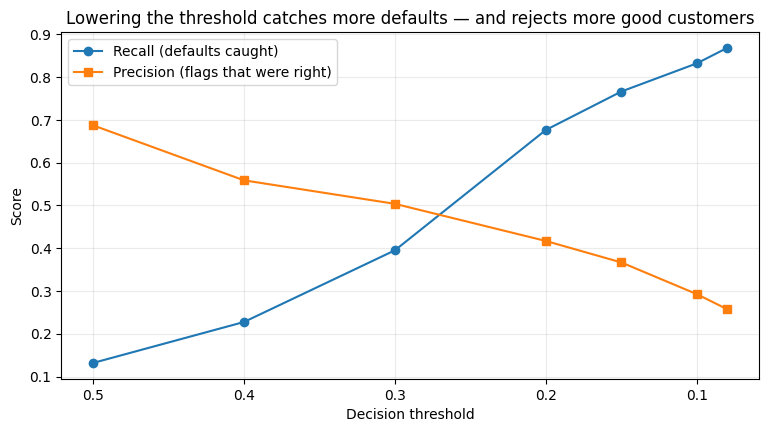

In [24]:
res = pd.DataFrame(rows)
plt.plot(res["threshold"], res["recall"], marker="o", label="Recall (defaults caught)")
plt.plot(res["threshold"], res["precision"], marker="s", label="Precision (flags that were right)")
plt.gca().invert_xaxis()
plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.title("Lowering the threshold catches more defaults — and rejects more good customers")
plt.legend()
plt.show()

**Discussion for the class.** A missed defaulter costs the bank the outstanding
principal. A rejected good applicant costs the margin we would have earned, plus the
relationship. Which is larger in your institution? That answer, not the algorithm,
sets the threshold.

## 10. Overfitting, demonstrated

We deliberately let a decision tree grow deeper and deeper, and watch what
happens to training performance versus test performance.

We plot **ROC AUC** alongside accuracy, because on imbalanced data the accuracy
curve is too flat to show the effect clearly.

In [25]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score

depths = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 30, None]
log = []

for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)

    p_train = tree.predict_proba(X_train)[:, 1]
    p_test  = tree.predict_proba(X_test)[:, 1]

    log.append({
        "max_depth":  "None" if d is None else d,
        "train_acc":  accuracy_score(y_train, tree.predict(X_train)),
        "test_acc":   accuracy_score(y_test,  tree.predict(X_test)),
        "train_auc":  roc_auc_score(y_train, p_train),
        "test_auc":   roc_auc_score(y_test,  p_test),
    })

curve = pd.DataFrame(log)
curve.round(3)

,max_depth,train_acc,test_acc,train_auc,test_auc
0,1,0.917,0.916,0.766,0.783
1,2,0.917,0.916,0.805,0.821
2,3,0.927,0.928,0.850,0.868
3,4,0.930,0.929,0.873,0.879
4,5,0.938,0.932,0.889,0.878
5,6,0.942,0.932,0.901,0.882
6,8,0.960,0.926,0.936,0.785
7,10,0.972,0.917,0.963,0.710
8,12,0.982,0.909,0.981,0.633
9,15,0.989,0.901,0.993,0.646


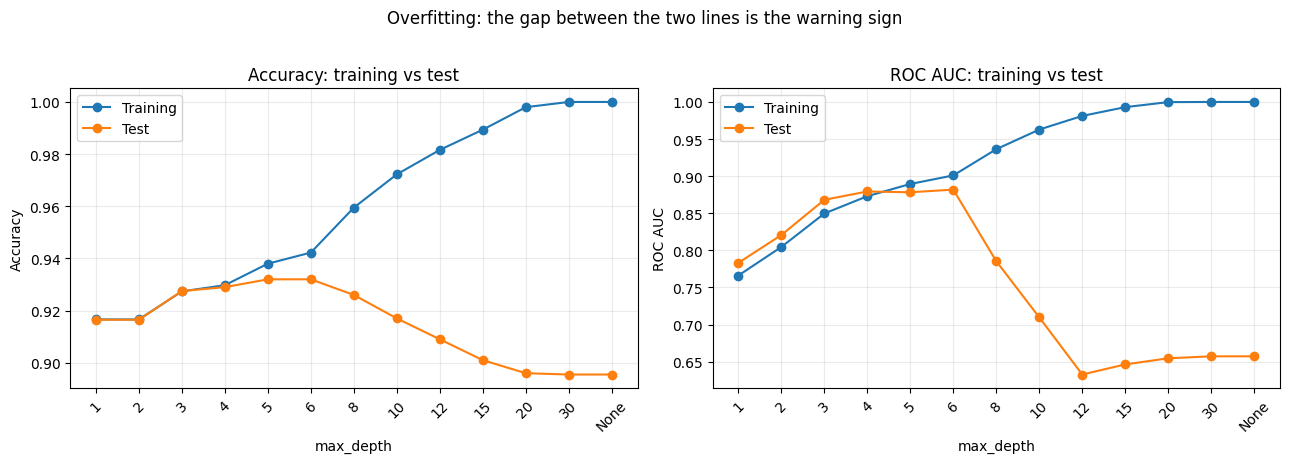

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
x = range(len(curve))

for ax, (a, b, name) in zip(axes, [("train_acc", "test_acc", "Accuracy"),
                                   ("train_auc", "test_auc", "ROC AUC")]):
    ax.plot(x, curve[a], marker="o", label="Training")
    ax.plot(x, curve[b], marker="o", label="Test")
    ax.set_xticks(list(x))
    ax.set_xticklabels(curve["max_depth"], rotation=45)
    ax.set_xlabel("max_depth")
    ax.set_ylabel(name)
    ax.set_title(f"{name}: training vs test")
    ax.legend()

plt.suptitle("Overfitting: the gap between the two lines is the warning sign", y=1.02)
plt.tight_layout()
plt.show()

In [27]:
best = curve.loc[curve["test_auc"].idxmax()]
print(f"Best test AUC at max_depth = {best['max_depth']}  ->  {best['test_auc']:.3f}")
print(f"At that depth, training AUC is {best['train_auc']:.3f}  "
      f"(train - test gap = {best['train_auc'] - best['test_auc']:+.3f} — essentially none)")

worst = curve.iloc[-1]
print(f"\nUnlimited depth:  training AUC {worst['train_auc']:.3f}, "
      f"test AUC {worst['test_auc']:.3f}  "
      f"(train - test gap = {worst['train_auc'] - worst['test_auc']:+.3f})")
print("\nThe unlimited tree has memorised the training rows. It has not learned anything extra.")

Best test AUC at max_depth = 6  ->  0.882
At that depth, training AUC is 0.901  (train - test gap = +0.019 — essentially none)

Unlimited depth:  training AUC 1.000, test AUC 0.657  (train - test gap = +0.343)

The unlimited tree has memorised the training rows. It has not learned anything extra.


### What you are looking at

The training line climbs toward a perfect score. The test line rises, peaks, and then
**falls away**. Everything to the right of that peak is memorisation, not learning.

**The fixes:** limit complexity (`max_depth`, `min_samples_leaf`), get more training
data, or use an ensemble. But first — always plot the two lines.

## Exercises

Work through these before Class 02.

1. Change `test_size` to `0.3` and re-run from section 4. What happens to the scores, and why?
2. Remove `stratify=y` and re-run a few times with different `random_state` values.
   How much does the test-set default rate move?
3. Put `days_past_due_final` back into the features. What is the ROC AUC now?
   Explain in one sentence why that number is a lie.
4. Fill the missing values with the **mean** instead of the median.
   Does any score change materially? Should it?
5. Train a `DecisionTreeClassifier(max_depth=4)` and compare its recall against
   logistic regression at the same threshold.

---

**Next class:** Types of Machine Learning, and Exploratory Data Analysis — where we go
back and do properly all the cleaning we rushed through in section 3.